<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Tarea 2, Structure from Motion**

Nombre(s):
* Franco Morero

**Objetivo**

Reconstruir una escena en 3D a partir de un video común, implementando paso a paso el flujo de Structure from Motion, y analizar cómo influye cada parámetro en la calidad de la reconstrucción.

**Descripción**

En este notebook se parte de un video en el que la cámara se desplaza alrededor de una escena. Del video se extraen las fotografías más nítidas y en cada una se detectan puntos característicos con SIFT. Los puntos se emparejan entre fotografías mediante el test de Lowe y se verifican con RANSAC. Las correspondencias se encadenan en tracks, y con el par inicial se estiman la pose relativa y una primera nube de puntos. Luego se incorporan las demás fotografías una a una, estimando su pose con PnP y triangulando nuevos puntos. El bundle adjustment refina en conjunto las cámaras, los puntos y la distancia focal. Al final se modifican los parámetros principales del flujo y se reconstruye una escena propia.

---
#### **Instrucciones:**
Utilice este notebook como base para realizar el TP2. Ejecútelo primero sin cambios y registre los resultados como línea de base. En cada ejercicio modifique solo lo indicado. Restablezca el valor original antes del siguiente ejercicio.

1. **Otro video (punto adicional con video propio)** Reconstruya otra escena con un video del repositorio de VGGT (https://github.com/facebookresearch/vggt/tree/main/examples/videos) o con un video propio.
¿Qué zonas de la escena tienen menos puntos y por qué?

2. **Cinco vecinos** En bf.knnMatch, reemplace k=2 por k=5.
¿Cambian los resultados? Explique por qué.

3. **Test de Lowe**: Reemplace 0.8 por 0.6 y luego por 0.95.

¿Cómo varían las parejas y los puntos 3D?
¿Por qué aceptar más parejas no produce más puntos?

4. **Menos features:** reemplace cv2.SIFT_create(3000) por cv2.SIFT_create(1000).

¿Qué ocurre con los puntos 3D y el tiempo?

5. **Menos fotografías:** Reemplace N = 24 por N = 12.

¿Se registran todas las cámaras?


6. **Ángulo de triangulación:** En triangular_nuevos, reemplace > 1.5 por > 3.

¿Cuántos puntos se pierden?
¿Por qué un ángulo pequeño da una profundidad poco confiable?

Entregue el notebook descargado en este link https://forms.gle/t1jjETaro6mfrdCY9 con las celdas ejecutadas, de modo que se vean las salidas, los gráficos y sus respuestas

---

**Este notebook reproduce el flujo visto en clase, pero aplicado a un video propio. Si graba su propio video, desplácese alrededor de la escena con lentitud, mantenga el enfoque y evite el zoom. El video usado en este notebook está en https://drive.google.com/file/d/1BjvKU6H2i85Fe0rU3-XfSFuzxwiXl--y/view?usp=sharing**


Sube tu video (mp4, mov...) añadiendo la ruta en "RUTA_VIDEO"

In [1]:
# !pip install -q pycolmap==4.2.1

RUTA_VIDEO = "llama.mp4"
if RUTA_VIDEO is None:
    from google.colab import files
    RUTA_VIDEO = list(files.upload().keys())[0]
print("video:", RUTA_VIDEO)

video: llama.mp4


importamos lo necesario

In [2]:
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix
from scipy.spatial.transform import Rotation

**0.- Las fotos**

* la cámara se mueve alrededor de la escena (tu video)
* cortamos el video en N tramos y en cada uno nos quedamos con el cuadro más nítido (varianza del Laplaciano)

393 cuadros en el video -> 24 fotos de 1280 × 720


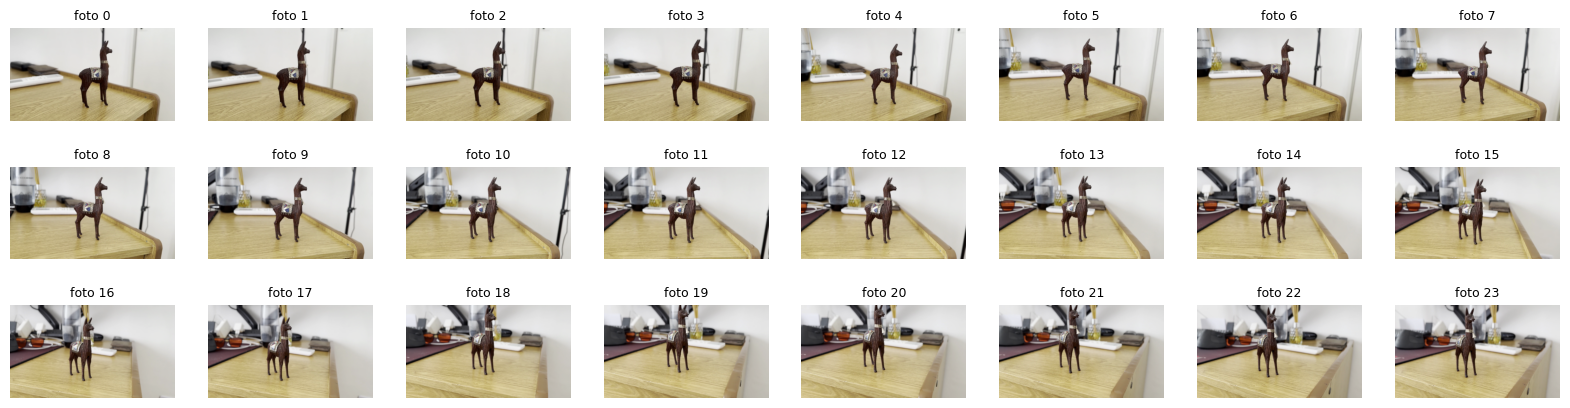

In [3]:
N = 24            # cuántas fotos sacamos del video (más fotos = más lento, pero modelo más completo)
ANCHO_MAX = 1280  # achicamos los cuadros grandes (4K/1080p) para que SIFT y el BA no tarden una eternidad
cap = cv2.VideoCapture(RUTA_VIDEO)
video = []
while True:
    ok, fr = cap.read()
    if not ok: break
    if fr.shape[1] > ANCHO_MAX:
        fr = cv2.resize(fr, (ANCHO_MAX, round(fr.shape[0] * ANCHO_MAX / fr.shape[1])), interpolation=cv2.INTER_AREA)
    video.append(fr)

# calculamos qué tan nítido es cada cuadro con la varianza del Laplaciano
# el Laplaciano resalta los bordes: una foto nítida tiene bordes marcados, así que la varianza da alta
# una foto movida o borrosa da baja
nitidez = [cv2.Laplacian(cv2.cvtColor(c, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var() for c in video]

# dividimos el video en N tramos y de cada tramo nos quedamos con el cuadro más nítido
elegidos = [t[np.argmax([nitidez[i] for i in t])] for t in np.array_split(np.arange(len(video)), N)]

# convertimos las fotos de BGR (el orden de colores de OpenCV) a RGB para mostrarlas
fotos = [cv2.cvtColor(video[k], cv2.COLOR_BGR2RGB) for k in elegidos]

# también generamos versiones en gris, porque SIFT trabaja en blanco y negro
grises = [cv2.cvtColor(f, cv2.COLOR_RGB2GRAY) for f in fotos]
H, W = grises[0].shape
print(f"{len(video)} cuadros en el video -> {N} fotos de {W} × {H}")

fig, ax = plt.subplots(int(np.ceil(N / 8)), 8, figsize=(20, 1.7 * np.ceil(N / 8)))
for k, a in enumerate(ax.ravel()):
    a.axis("off")
    if k < N: a.imshow(fotos[k]); a.set_title(f"foto {k}", fontsize=9)
plt.show()

**1.- Features**

puntos distintivos en cada foto

SIFT busca en cada foto puntos que se puedan volver a encontrar desde otro lugar: esquinas y manchas, a la escala en que aparecen.

Cada uno tiene una posición, una escala, una orientación y un descriptor de 128 números

In [4]:
# buscamos hasta 3000 puntos característicos por foto: esquinas o manchas que se
# pueden reconocer aunque la foto se haya tomado desde otro lugar
sift = cv2.SIFT_create(3000)

# para cada foto devuelve:
# kps (keypoints): posición, escala (tamaño) y orientación de cada punto
# descs: un descriptor de 128 números por punto, funciona como una “huella digital” del punto
kps, descs = zip(*[sift.detectAndCompute(g, None) for g in grises])

# xy guarda solo las coordenadas (u, v) en píxeles
xy = [np.float64([k.pt for k in ks]) for ks in kps]
print(f"features por foto: entre {min(map(len, kps))} y {max(map(len, kps))}")

features por foto: entre 687 y 1132


los features de la primera foto: el círculo es la escala y la línea la orientación

se concentran donde hay textura (la llama, los objetos del escritorio) y casi no hay en la pared lisa o en la mesa

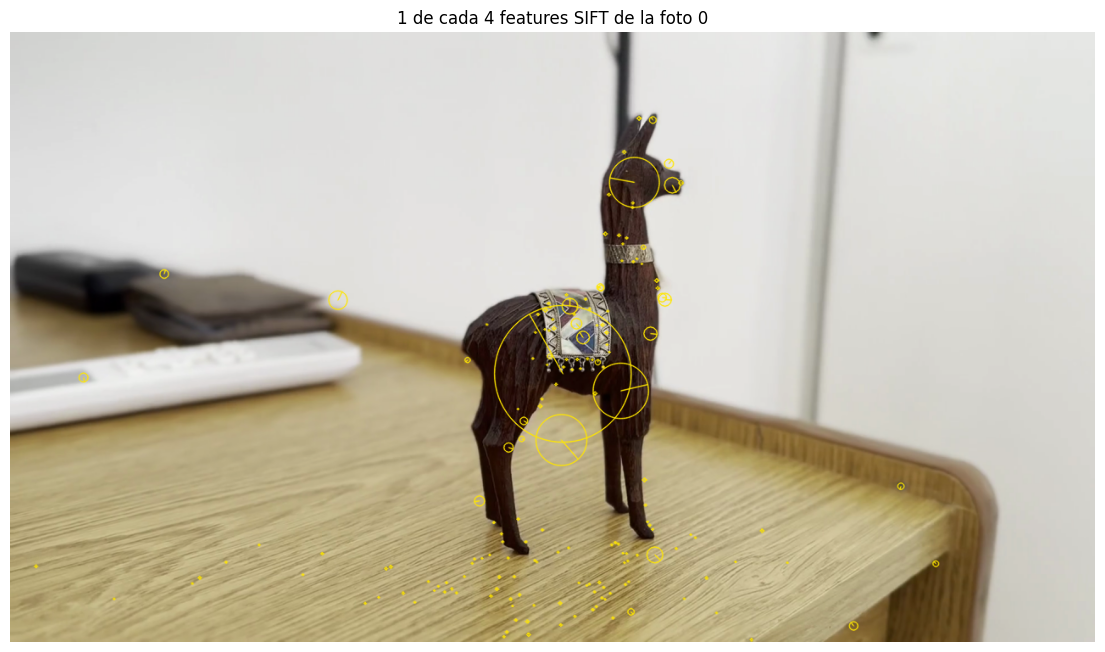

In [5]:
vis = cv2.drawKeypoints(fotos[0], kps[0][::4], None, color=(255, 230, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(14, 8))
plt.imshow(vis)
plt.axis("off")
plt.title("1 de cada 4 features SIFT de la foto 0")
plt.show()

**2.- Matching**

el mismo punto en dos fotos

para cada par de fotos:
* para cada descriptor de una foto buscamos los 2 más parecidos en la otra
* **test de Lowe:** aceptamos si el mejor es claramente mejor que el segundo (distancia < 0.8 × la segunda)
* **RANSAC** sobre la matriz fundamental: descartamos las parejas que no cumplen x₂ᵀ F x₁ = 0

como es un video, comparamos cada foto con las 10 siguientes

In [6]:
bf = cv2.BFMatcher()
def emparejar(i, j):
    # Buscamos los 2 descriptores más parecidos y aplicamos el test de Lowe
    ms = [m for m, n in bf.knnMatch(descs[i], descs[j], k=2) if m.distance < 0.8 * n.distance]
    a = np.array([m.queryIdx for m in ms])
    b = np.array([m.trainIdx for m in ms])

    if len(ms) < 20:
      return None

    # Estimamos la matriz fundamental F con RANSAC y descartamos las parejas que no cumplen la geometría
    F, ok = cv2.findFundamentalMat(xy[i][a], xy[j][b], cv2.FM_RANSAC, 1.0, 0.999)
    if F is None:
      return None
    ok = ok.ravel() > 0
    return {"a": a, "b": b, "ok": ok, "F": F}


VENTANA = 10  # con cuántas fotos siguientes comparamos cada una (subilo a N si tu video vuelve al punto de partida)
t0 = time.time()
pares = {}
for i in range(N):
    # Comparamos cada foto con las VENTANA siguientes
    for j in range(i + 1, min(i + 1 + VENTANA, N)):
        r = emparejar(i, j)
        # Guardamos el par solo si tiene al menos 10 parejas verificadas
        if r is not None and r["ok"].sum() >= 10:
          pares[(i, j)] = r
print(f"{len(pares)} pares con al menos 10 parejas verificadas | {time.time() - t0:.1f} s")

185 pares con al menos 10 parejas verificadas | 1.2 s


un par de fotos: en verde las parejas que pasaron RANSAC, en rojo las que pasaron Lowe pero no la geometría

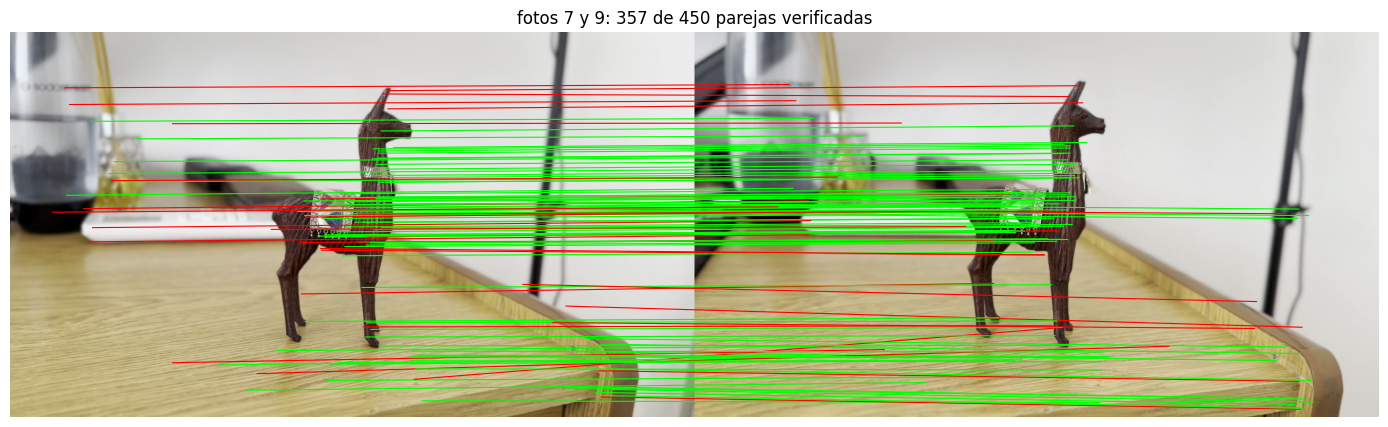

In [7]:
def dibujar_par(i, j, n=120):
    r = pares[(i, j)]
    # Elegimos al azar hasta 120 parejas para no saturar el dibujo
    sel = np.random.default_rng(0).choice(len(r["a"]), min(n, len(r["a"])), replace=False)
    # Ponemos las dos fotos lado a lado
    plt.figure(figsize=(18, 5)); plt.imshow(np.hstack([fotos[i], fotos[j]])); plt.axis("off")
    for k in sel:
        p, q = xy[i][r["a"][k]], xy[j][r["b"][k]]
        # Unimos cada pareja con una línea: verde si pasó RANSAC, roja si no (sumamos W porque la segunda foto está a la derecha)
        plt.plot([p[0], q[0] + W], [p[1], q[1]], color="lime" if r["ok"][k] else "red", lw=0.8)
    plt.title(f"fotos {i} y {j}: {r['ok'].sum()} de {len(r['a'])} parejas verificadas")
    plt.show()

# dibujamos el par con más parejas verificadas entre fotos separadas por al menos 2 cuadros
par_demo = max([k for k in pares if k[1] - k[0] >= 2] or list(pares), key=lambda k: pares[k]["ok"].sum())
dibujar_par(*par_demo)

cuántas parejas verificadas hay entre cada par de fotos. Las fotos cercanas en el video comparten mucho; a medida que la cámara gira, cada vez menos

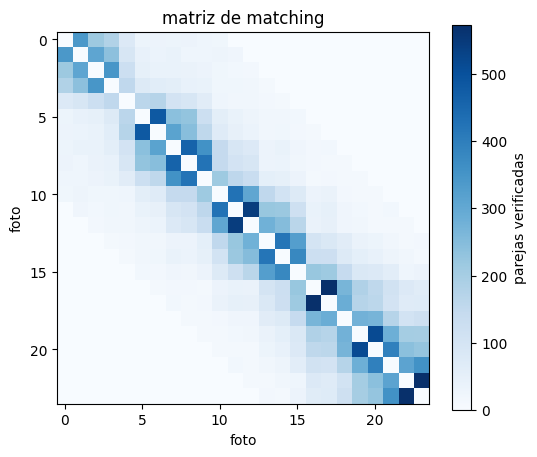

In [8]:
M = np.zeros((N, N))
# Llenamos la matriz con la cantidad de parejas verificadas de cada par (es simétrica)
for (i, j), r in pares.items(): M[i, j] = M[j, i] = r["ok"].sum()
# Mostramos la matriz como imagen: más oscuro = más parejas en común
plt.figure(figsize=(6, 5)); plt.imshow(M, cmap="Blues"); plt.colorbar(label="parejas verificadas")
plt.xlabel("foto")
plt.ylabel("foto")
plt.title("matriz de matching")
plt.show()

**tracks:** encadenamos las parejas. Si el feature 12 de la foto 0 es el 40 de la foto 1, y ese es el 7 de la foto 2, los tres son el **mismo punto 3D**. Lo hacemos con union-find: cada feature arranca en su propio grupo y cada pareja une dos grupos

3764 tracks | largo medio 3.6 fotos | el más largo: 19 fotos


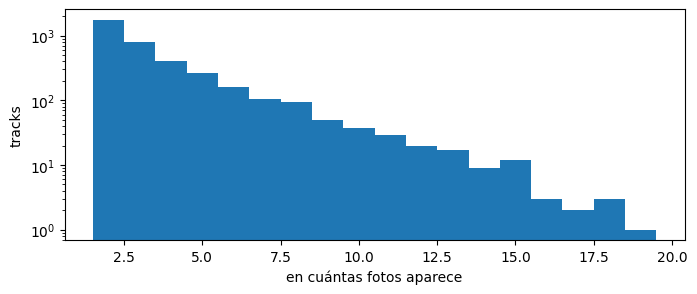

In [9]:
padre = {}
# Buscamos la raíz del grupo de un nodo y acortamos el camino para que sea más rápido
def raiz(n):
    while padre.setdefault(n, n) != n:
        padre[n] = padre[padre[n]]
        n = padre[n]
    return n

# Unimos en un mismo grupo cada pareja verificada (un nodo es (foto, índice del feature))
for (i, j), r in pares.items():
    for p, q in zip(r["a"][r["ok"]], r["b"][r["ok"]]):
        padre[raiz((i, p))] = raiz((j, q))

grupos = {}
for n in list(padre):
  grupos.setdefault(raiz(n), []).append(n)

# Nos quedamos con los grupos que no tienen dos features de la misma foto: cada uno es un track
tracks = [sorted(g) for g in grupos.values() if len(g) >= 2 and len({f for f, _ in g}) == len(g)]

# Armamos el índice inverso: para cada foto, de feature a track
track_de = [dict() for _ in range(N)]
for t, g in enumerate(tracks):
    for f, k in g:
      track_de[f][k] = t

largos = np.array([len(t) for t in tracks])

print(f"{len(tracks)} tracks | largo medio {largos.mean():.1f} fotos | el más largo: {largos.max()} fotos")
# Graficamos en cuántas fotos aparece cada track
plt.figure(figsize=(8, 3))
plt.hist(largos, bins=np.arange(2, largos.max() + 2) - 0.5)
plt.xlabel("en cuántas fotos aparece")
plt.ylabel("tracks")
plt.yscale("log")
plt.show()

**un punto, muchas fotos:** el track más largo. Es el mismo lugar del mundo visto desde todo el recorrido de la cámara

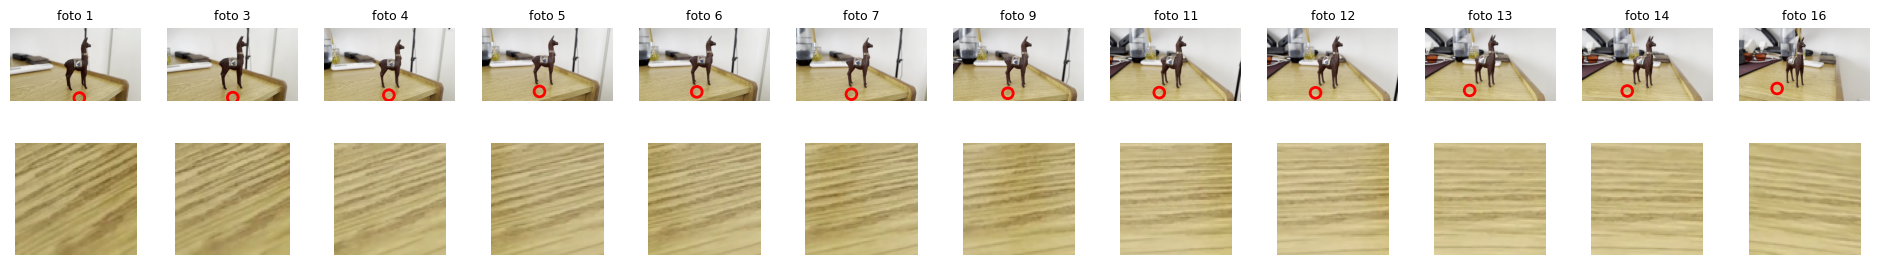

In [10]:
# Buscamos el track más largo
t = int(np.argmax(largos))
# Tomamos hasta 12 de sus observaciones, repartidas a lo largo del recorrido
obs = tracks[t][:: max(1, len(tracks[t]) // 12)][:12]
fig, ax = plt.subplots(2, len(obs), figsize=(2 * len(obs), 3.2))
for k, (f, i) in enumerate(obs):
    u, v = xy[f][i]
    # Arriba: marcamos el punto con un círculo rojo en la foto completa
    ax[0, k].imshow(fotos[f]); ax[0, k].scatter(u, v, s=60, facecolors="none", edgecolors="red", lw=2)
    # Abajo: hacemos zoom recortando 40 px alrededor del punto
    ax[1, k].imshow(fotos[f][max(0, int(v) - 40):int(v) + 40, max(0, int(u) - 40):int(u) + 40])
    ax[0, k].set_title(f"foto {f}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.show()

**3.- Geometría de dos vistas**

E, R y t entre cámaras

* arrancamos con un par de fotos

* tiene que tener muchas parejas, pero también buena separación: con fotos casi iguales los rayos son paralelos y la triangulación es mala

* no conocemos K

* suponemos el centro óptico en el medio de la imagen, la focal la vemos enseguida

In [11]:
# Armamos la matriz de calibración K con la focal f y el centro en el medio de la imagen
def K_de(f):
    return np.array([[f, 0, W / 2], [0, f, H / 2], [0, 0, 1]])

# Triangulamos con DLT: cada observación aporta 2 filas a A y el punto 3D es el último vector singular
def triangular(Ps, uvs):
    A = np.concatenate([np.stack([uv[:, :1] * P[2] - P[0], uv[:, 1:] * P[2] - P[1]], 1) for P, uv in zip(Ps, uvs)], 1)
    X = np.linalg.svd(A)[2][:, -1]
    return X[:, :3] / X[:, 3:]

# Proyectamos puntos 3D en la cámara P: devolvemos el píxel y la profundidad
def proyectar_P(P, X):
    h = np.c_[X, np.ones(len(X))] @ P.T
    return h[:, :2] / h[:, 2:], h[:, 2]

def dos_vistas(i, j, f):
    r = pares[(i, j)]
    p, q = xy[i][r["a"][r["ok"]]], xy[j][r["b"][r["ok"]]]
    K = K_de(f)
    # Calculamos E = Kᵀ F K y recuperamos la pose (R, t) que deja los puntos delante de las cámaras
    _, R, t, _ = cv2.recoverPose(K.T @ r["F"] @ K, p, q, K)
    # Ubicamos la primera cámara en el origen y la segunda con (R, t)
    P1, P2 = K @ np.c_[np.eye(3), np.zeros(3)], K @ np.c_[R, t]
    X = triangular([P1, P2], [p, q])
    # Medimos el error de reproyección promedio entre las dos fotos
    e = (np.linalg.norm(proyectar_P(P1, X)[0] - p, axis=1) + np.linalg.norm(proyectar_P(P2, X)[0] - q, axis=1)) / 2
    # Calculamos el ángulo entre los rayos de las dos cámaras hacia cada punto
    C2 = -R.T @ t.ravel()
    cos = (X * (X - C2)).sum(1) / np.linalg.norm(X, axis=1) / np.linalg.norm(X - C2, axis=1)
    return R, t.ravel(), np.median(e), np.degrees(np.median(np.arccos(np.clip(cos, -1, 1))))

las rectas epipolares de ese par: cada punto de la foto izquierda tiene que tener su pareja sobre la recta del mismo color

par inicial: fotos 19 y 23 | 201 parejas | ángulo mediano 7.8°


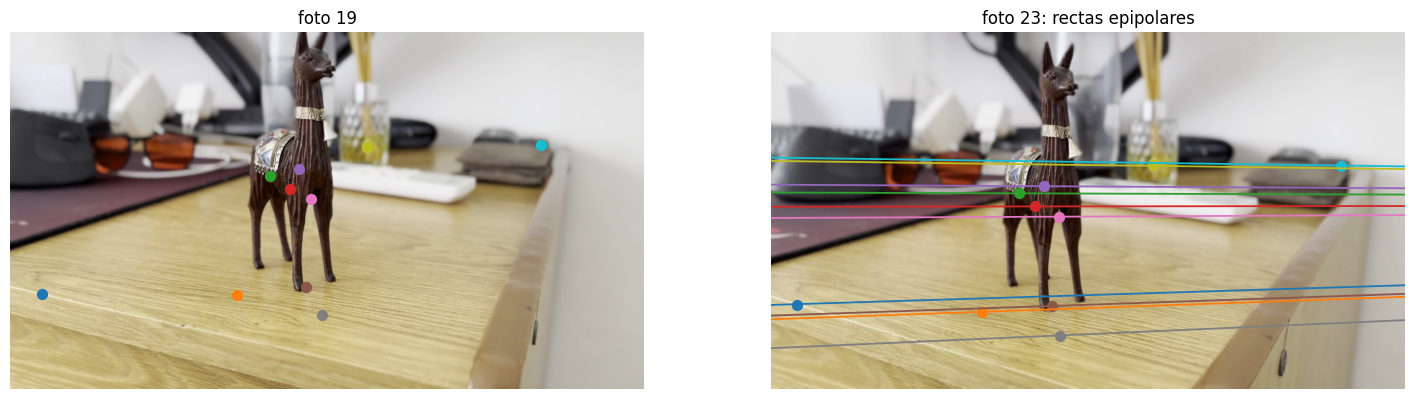

In [12]:
f_ini = 1.2 * max(W, H)

f0 = 1.2 * W
candidatos = []
for (i, j), r in pares.items():
    if 4 <= j - i <= 10:
        _, _, _, ang = dos_vistas(i, j, f0)
        candidatos.append((r["ok"].sum() if ang > 3 else 0, i, j, ang))
# si tu video no tiene pares separados entre 4 y 10 fotos (pocas fotos, o mucho movimiento), probamos con todos
if not candidatos:
    for (i, j), r in pares.items():
        _, _, _, ang = dos_vistas(i, j, f0)
        candidatos.append((r["ok"].sum() if ang > 3 else 0, i, j, ang))
_, A0, B0, ang = max(candidatos)
print(f"par inicial: fotos {A0} y {B0} | {pares[(A0, B0)]['ok'].sum()} parejas | ángulo mediano {ang:.1f}°")

focales = np.arange(0.4, 2.01, 0.05) * W  # rango relativo al ancho, así sirve para cualquier resolución
errores = [dos_vistas(A0, B0, f)[2] for f in focales]
f_ini = focales[np.argmin(errores)]  # la focal que mejor reproyecta el par inicial (una fija 1.2·W falla según la cámara)

r = pares[(A0, B0)]
# Tomamos las parejas verificadas del par inicial
p, q = xy[A0][r["a"][r["ok"]]], xy[B0][r["b"][r["ok"]]]
# Elegimos 10 parejas repartidas para dibujar
sel = np.linspace(0, len(p) - 1, 10).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].imshow(fotos[A0]); ax[1].imshow(fotos[B0])
for c, k in zip(plt.cm.tab10(np.arange(10)), sel):
    # Calculamos la recta epipolar l = F·p del punto de la foto izquierda
    l = r["F"] @ [*p[k], 1]; u = np.array([0, W])
    # Dibujamos la recta en la foto derecha despejando v de la ecuación de la recta
    ax[1].plot(u, -(l[0] * u + l[2]) / l[1], color=c, lw=1.3)
    # Marcamos el punto y su pareja con el mismo color: la pareja debe caer sobre la recta
    ax[0].scatter(*p[k], color=c, s=50)
    ax[1].scatter(*q[k], color=c, s=50)
for a, tt in zip(ax, [f"foto {A0}", f"foto {B0}: rectas epipolares"]):
    a.set_xlim(0, W)
    a.set_ylim(H, 0)
    a.axis("off")
    a.set_title(tt)
plt.show()

E = Kᵀ F K tiene **4** descomposiciones posibles en (R, t). Solo una deja los puntos delante de las dos cámaras

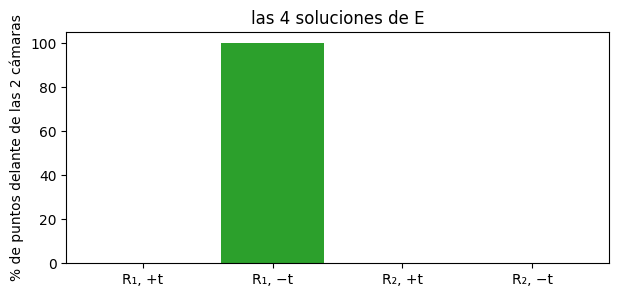

la cámara 23 giró 5.0° | t = [-0.987  0.003 -0.159] (norma 1: sin escala)


In [13]:
K = K_de(f_ini)

# Descomponemos E en sus 2 rotaciones posibles y la dirección de t
R1, R2, tt = cv2.decomposeEssentialMat(K.T @ r["F"] @ K)
P1 = K @ np.c_[np.eye(3), np.zeros(3)]
nombres, delante = [], []

# Probamos las 4 combinaciones de (R, t)
for nombre, R, t in [("R₁, +t", R1, tt), ("R₁, −t", R1, -tt), ("R₂, +t", R2, tt), ("R₂, −t", R2, -tt)]:
    X = triangular([P1, K @ np.c_[R, t]], [p, q])
    # Contamos qué porcentaje de puntos queda delante de las dos cámaras (z > 0 en ambas)
    nombres.append(nombre)
    delante.append(((X[:, 2] > 0) & ((X @ R.T + t.T)[:, 2] > 0)).mean() * 100)

# Graficamos y resaltamos en verde la única solución válida
plt.figure(figsize=(7, 3))
plt.bar(nombres, delante, color=["tab:green" if d == max(delante) else "tab:gray" for d in delante])
plt.ylabel("% de puntos delante de las 2 cámaras")
plt.title("las 4 soluciones de E"); plt.show()

# Calculamos la pose inicial con la focal elegida y mostramos cuánto giró la segunda cámara
R_ini, t_ini, e_ini, _ = dos_vistas(A0, B0, f_ini)
print(f"la cámara {B0} giró {np.degrees(np.arccos((np.trace(R_ini) - 1) / 2)):.1f}° | t = {t_ini.round(3)} (norma 1: sin escala)")

**4.- Triangulación**


los puntos 3D

el estado de nuestra reconstrucción:
* **camaras:** para cada foto registrada, su pose como 6 números (rotación de Rodrigues + traslación)
* **puntos:** para cada track triangulado, su posición 3D
* **f:** la focal, compartida por todas las fotos

usamos la cámara de la primera foto (A0) como referencia para definir las coordenadas 3D

In [14]:
# Guardamos cada cámara como 6 números (rotación + traslación): A0 queda en el origen
camaras = {A0: np.zeros(6), B0: np.r_[Rotation.from_matrix(R_ini).as_rotvec(), t_ini]}
puntos = {} # Guardamos aquí la posición 3D de cada track triangulado
f = f_ini # Usamos una sola focal para todas las fotos

# Armamos la matriz de proyección P = K [R | t] a partir de los 6 números
def P_de(c, f):
    return K_de(f) @ np.c_[Rotation.from_rotvec(c[:3]).as_matrix(), c[3:]]

# Calculamos dónde está la cámara en el mundo: C = −Rᵀ t
def centro(c):
    return -Rotation.from_rotvec(c[:3]).as_matrix().T @ c[3:]

Reconstruimos nuevos puntos 3D a partir de las correspondencias (tracks) observadas en al menos dos cámaras registradas:

1. Busca candidatos: identifica tracks que todavía no tienen coordenadas 3D y aparecen en al menos dos cámaras
2. Triangula: utiliza las matrices de proyección de las cámaras y DLT para calcular la posición 3D de cada punto
3. Valida los resultados: descarta puntos que estén detrás de alguna cámara o tengan un error de reproyección superior a 4 píxeles
4. Comprueba la geometría: exige un ángulo de triangulación superior a 1.5° para evitar reconstrucciones poco fiables
5. Guarda los puntos válidos: almacena sus coordenadas 3D en puntos

In [15]:
def triangular_nuevos():
    # Buscamos los tracks sin punto 3D que aparecen en al menos 2 cámaras registradas
    cand = [t for t, g in enumerate(tracks) if t not in puntos and sum(fr in camaras for fr, _ in g) >= 2]
    nuevos = 0
    # Agrupamos por cantidad de observaciones para triangular muchos a la vez
    for n_obs in {sum(fr in camaras for fr, _ in tracks[t]) for t in cand}:
        ts = [t for t in cand if sum(fr in camaras for fr, _ in tracks[t]) == n_obs]
        obs = [[(fr, k) for fr, k in tracks[t] if fr in camaras] for t in ts]
        Ps = [[P_de(camaras[fr], f) for fr, _ in o] for o in obs]
        # Triangulamos con DLT: armamos A para cada track y resolvemos todo con una sola SVD
        A = np.array([np.concatenate([[x[0] * P[2] - P[0], x[1] * P[2] - P[1]] for P, (fr, k) in zip(Pl, o) for x in [xy[fr][k]]]) for Pl, o in zip(Ps, obs)])
        Xh = np.linalg.svd(A)[2][:, -1]; X = Xh[:, :3] / Xh[:, 3:]
        for t, o, x in zip(ts, obs, X):
            ok, rayos = True, []
            for fr, k in o:
                uv, z = proyectar_P(P_de(camaras[fr], f), x[None])
                # Descartamos el punto si queda detrás de una cámara o tiene más de 4 px de error
                if z[0] <= 0 or np.linalg.norm(uv[0] - xy[fr][k]) > 4: ok = False; break
                rayos.append((x - centro(camaras[fr])) / np.linalg.norm(x - centro(camaras[fr])))
            # Aceptamos el punto solo si el ángulo máximo entre rayos supera 1.5°
            if ok and np.degrees(np.arccos(np.clip(min(a @ b for a in rayos for b in rayos), -1, 1))) > 1.5:
                puntos[t] = x; nuevos += 1
    return nuevos

print(f"puntos triangulados con 2 fotos: {triangular_nuevos()}")

puntos triangulados con 2 fotos: 187


vemos los puntos
* obtenemos los colores directamente de los píxeles de las fotografías originales

* para cada track toma el color del píxel correspondiente a su primera observación (g[0]) en la primera fotografía donde aparece

* cada punto 3D se visualiza con un color similar al que tenía en la imagen original
* las cámaras obtienen sus coordenadas a partir de sus parámetros de rotación y traslación, almacenados en el diccionario camaras

In [16]:
# Tomamos el color de cada track del píxel de la primera foto donde aparece
color_track = np.array([fotos[g[0][0]][int(xy[g[0][0]][g[0][1]][1]), int(xy[g[0][0]][g[0][1]][0])] for g in tracks]) / 255

# Dibujamos cada cámara como una pirámide: el vértice es el centro óptico y la base es la imagen
def piramide(c, f, tam):
    R = Rotation.from_rotvec(c[:3]).as_matrix(); C = centro(c)
    # Proyectamos las 4 esquinas de la imagen hacia adelante y las pasamos al sistema del mundo
    esquinas = np.array([[0, 0, 1], [W, 0, 1], [W, H, 1], [0, H, 1]]) @ np.linalg.inv(K_de(f)).T * tam
    E = esquinas @ R + C
    L = [C, E[0], None, C, E[1], None, C, E[2], None, C, E[3], None, E[0], E[1], E[2], E[3], E[0], None]
    return [(np.full(3, np.nan) if p is None else p) for p in L]

# Reordenamos los ejes a (X, Z, −Y) para que "arriba" quede hacia arriba en el gráfico
def a_vista(P):
    P = np.asarray(P); return P[:, 0], P[:, 2], -P[:, 1]

def figura(camaras, puntos, f, titulo, tam=None, max_puntos=6000):
    ts = np.array(sorted(puntos)); X = np.array([puntos[t] for t in ts])
    # Limitamos la cantidad de puntos para que el gráfico no se vuelva lento
    if len(ts) > max_puntos:
        k = np.random.default_rng(0).choice(len(ts), max_puntos, replace=False); ts, X = ts[k], X[k]
    tam = tam or 0.15 * np.median(np.linalg.norm(X - centro(camaras[A0]), axis=1))
    lineas = [p for c in camaras.values() for p in piramide(c, f, tam)]
    col = [f"rgb({r * 255:.0f},{g * 255:.0f},{b * 255:.0f})" for r, g, b in color_track[ts]]
    # Devolvemos los puntos con su color y las cámaras en rojo
    return [go.Scatter3d(x=a_vista(X)[0], y=a_vista(X)[1], z=a_vista(X)[2], mode="markers", marker=dict(size=1.5, color=col), name="puntos"),
            go.Scatter3d(x=a_vista(lineas)[0], y=a_vista(lineas)[1], z=a_vista(lineas)[2], mode="lines", line=dict(color="crimson", width=3), name="cámaras")]

fig = go.Figure(figura(camaras, puntos, f, ""))
fig.update_layout(height=550, title=f"2 cámaras y {len(puntos)} puntos", scene=dict(aspectmode="data", xaxis_visible=False, yaxis_visible=False, zaxis_visible=False), margin=dict(l=0, r=0, t=40, b=0))
fig.show()

**5.- Bundle Adjustment**


refinar todo junto

ajustamos **todo junto**: las poses de las cámaras registradas, los puntos y la focal, para minimizar el error de reproyección

Σ ‖ xᵢⱼ − π(f, Rᵢ, tᵢ, Xⱼ) ‖²

* la cámara A0 queda fija: es el origen del mundo
* el jacobiano es disperso: cada residuo depende de su cámara, su punto y la focal (notebook 2)
* las parejas malas que se colaron no las ablandamos con una pérdida robusta: después de cada ajuste borramos los puntos con alguna observación de más de 4 px

In [17]:
# Listamos todas las observaciones: qué cámara (ic), qué punto (ip) y dónde se midió (uv)
def observaciones():
    libres = [fr for fr in sorted(camaras) if fr != A0] # Ajustamos todas las cámaras menos A0
    ts = sorted(puntos)
    ic, ip, uv = [], [], []
    for n, t in enumerate(ts):
        for fr, k in tracks[t]:
            if fr in camaras:
                ic.append(-1 if fr == A0 else libres.index(fr)); ip.append(n); uv.append(xy[fr][k])
    return libres, ts, np.array(ic), np.array(ip), np.array(uv)

# Proyectamos todos los puntos en sus cámaras de una sola vez
def proyectar(cam, f, X, ic, ip):
    cam = np.r_[cam, np.zeros((1, 6))] # Usamos el índice −1 para la cámara fija A0
    Xc = Rotation.from_rotvec(cam[ic, :3]).apply(X[ip]) + cam[ic, 3:]
    return f * Xc[:, :2] / Xc[:, 2:] + [W / 2, H / 2]

# Medimos la distancia en píxeles entre lo proyectado y lo medido
def error_reproyeccion():
    libres, ts, ic, ip, uv = observaciones()
    cam = np.array([camaras[fr] for fr in libres]).reshape(-1, 6); X = np.array([puntos[t] for t in ts])
    return np.linalg.norm(proyectar(cam, f, X, ic, ip) - uv, axis=1)

def bundle_adjustment(max_iter=20, fijar_f=False):
    global f
    libres, ts, ic, ip, uv = observaciones()
    nc, npt, nf = len(libres), len(ts), 0 if fijar_f else 1
    # Definimos los residuos: la diferencia entre la proyección y la medición
    def residuos(v):
        ff = f if fijar_f else v[6 * nc]
        return (proyectar(v[:6 * nc].reshape(nc, 6), ff, v[6 * nc + nf:].reshape(npt, 3), ic, ip) - uv).ravel()
    # Armamos la matriz dispersa: cada residuo depende solo de su cámara, su punto y la focal
    A = lil_matrix((2 * len(uv), 6 * nc + nf + 3 * npt), dtype=int)
    filas = np.arange(len(uv)); libre = ic >= 0
    for s in range(6):
        A[2 * filas[libre], 6 * ic[libre] + s] = 1; A[2 * filas[libre] + 1, 6 * ic[libre] + s] = 1
    if nf: A[:, 6 * nc] = 1
    for s in range(3):
        A[2 * filas, 6 * nc + nf + 3 * ip + s] = 1; A[2 * filas + 1, 6 * nc + nf + 3 * ip + s] = 1
    # Juntamos todas las variables en un vector: cámaras, focal y puntos
    v0 = np.r_[np.array([camaras[fr] for fr in libres]).ravel(), [f] * nf, np.array([puntos[t] for t in ts]).ravel()]
    # Optimizamos todo junto por mínimos cuadrados
    sol = least_squares(residuos, v0, jac_sparsity=A, method="trf", x_scale="jac", max_nfev=max_iter)
    # Guardamos los valores ajustados
    for k, fr in enumerate(libres): camaras[fr] = sol.x[6 * k:6 * k + 6]
    if nf: f = sol.x[6 * nc]
    for k, t in enumerate(ts): puntos[t] = sol.x[6 * nc + nf + 3 * k:6 * nc + nf + 3 * k + 3]

# Borramos los puntos con alguna observación de más de `umbral` px
def limpiar(umbral=4):
    libres, ts, ic, ip, uv = observaciones()
    e = error_reproyeccion()
    malos = np.unique(ip[e > umbral])
    for n in malos: del puntos[ts[n]]
    return len(malos)

con solo 2 fotos ya hay algo para ajustar

In [18]:
e0 = error_reproyeccion().mean() # Medimos el error antes de ajustar
bundle_adjustment() # Ajustamos cámaras, puntos y focal con solo 2 fotos
# Comparamos el error y la focal antes y después del ajuste
print(f"error de reproyección: {e0:.2f} px -> {error_reproyeccion().mean():.2f} px | focal {f_ini:.0f} -> {f:.0f} px")

error de reproyección: 0.73 px -> 0.16 px | focal 960 -> 945 px


**6.- SfM incremental**

ahora repetimos foto por foto:
1. elegimos la foto no registrada que ve más puntos 3D ya triangulados
2. estimamos la pose de la nueva cámara utilizando puntos 3D conocidos y sus correspondencias 2D en la nueva fotografía
3. triangulamos los tracks nuevos que ahora ven 2 fotos registradas
4. bundle adjustment de todo, y limpiamos puntos malos

guardamos una foto del estado en cada paso para animarlo

In [19]:
def registrar_siguiente():
    K = K_de(f)
    mejor = None
    # Buscamos la foto no registrada que ve más puntos 3D ya triangulados
    for fr in range(N):
        if fr in camaras:
          continue
        pares2d3d = [(k, t) for k, t in track_de[fr].items() if t in puntos]
        if mejor is None or len(pares2d3d) > len(mejor[1]):
          mejor = (fr, pares2d3d)
    fr, p2d3d = mejor
    if len(p2d3d) < 30:
      return None
    obj = np.array([puntos[t] for _, t in p2d3d]); img = np.array([xy[fr][k] for k, _ in p2d3d])
    # Estimamos la pose de la foto nueva con PnP + RANSAC a partir de las parejas 2D–3D
    ok, rvec, tvec, inl = cv2.solvePnPRansac(obj, img, K, None, iterationsCount=500, reprojectionError=4.0)
    if not ok or inl is None or len(inl) < 30:
      return None
    camaras[fr] = np.r_[rvec.ravel(), tvec.ravel()] # Registramos la cámara nueva
    return fr, len(p2d3d), len(inl)

historia = [(dict(camaras), dict(puntos), f, "inicio")] # Guardamos cada estado para la animación
filas = []
t0 = time.time()
# Repetimos foto por foto hasta registrar todas
while len(camaras) < N:
    r = registrar_siguiente()
    if r is None:
      print("ninguna foto más se puede registrar")
      break
    fr, n2d3d, n_inl = r
    nuevos = triangular_nuevos() # Triangulamos los puntos que ahora ven 2 cámaras
    antes = error_reproyeccion().mean()
    bundle_adjustment(max_iter=10) # Ajustamos todo junto
    borrados = limpiar() # Borramos los puntos malos
    despues = error_reproyeccion().mean()
    filas.append((len(camaras), fr, n2d3d, n_inl, nuevos, len(puntos), antes, despues, f))
    historia.append((dict(camaras), dict(puntos), f, f"+ foto {fr}"))
    print(f"{len(camaras):2d} cámaras | + foto {fr:2d} | PnP: {n_inl:4d}/{n2d3d:4d} inliers | +{nuevos:4d} puntos | total {len(puntos):5d} | error {antes:.2f} -> {despues:.2f} px | f {f:.0f} px")
print(f"listo en {time.time() - t0:.0f} s")

 3 cámaras | + foto 21 | PnP:  148/ 149 inliers | + 245 puntos | total   431 | error 0.24 -> 0.23 px | f 1018 px
 4 cámaras | + foto 20 | PnP:  285/ 285 inliers | +  75 puntos | total   506 | error 0.26 -> 0.21 px | f 1058 px
 5 cámaras | + foto 22 | PnP:  308/ 308 inliers | +  54 puntos | total   560 | error 0.23 -> 0.22 px | f 1049 px
 6 cámaras | + foto 18 | PnP:  210/ 214 inliers | + 144 puntos | total   703 | error 0.33 -> 0.30 px | f 1059 px
 7 cámaras | + foto 17 | PnP:  213/ 231 inliers | + 125 puntos | total   826 | error 0.36 -> 0.29 px | f 1089 px
 8 cámaras | + foto 16 | PnP:  312/ 316 inliers | +  53 puntos | total   877 | error 0.32 -> 0.31 px | f 1096 px
 9 cámaras | + foto 15 | PnP:  198/ 207 inliers | + 116 puntos | total   989 | error 0.36 -> 0.32 px | f 1090 px
10 cámaras | + foto 14 | PnP:  194/ 199 inliers | + 196 puntos | total  1169 | error 0.58 -> 0.62 px | f 1413 px
11 cámaras | + foto 13 | PnP:  256/ 274 inliers | + 207 puntos | total  1318 | error 0.92 -> 0.8

**la animación:** cada cuadro es el estado después de agregar una foto

In [20]:
# Calculamos límites fijos para los ejes, así la vista no salta entre cuadros
def ejes_de(camaras, puntos):
    X = np.array(list(puntos.values()) + [centro(c) for c in camaras.values()])
    # Usamos los percentiles 1 y 99 para ignorar puntos sueltos y agregamos un margen del 10 %
    lo, hi = np.percentile(X, 1, axis=0), np.percentile(X, 99, axis=0)
    pad = 0.1 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    return dict(xaxis=dict(range=[lo[0], hi[0]], visible=False), yaxis=dict(range=[lo[2], hi[2]], visible=False),
                zaxis=dict(range=[-hi[1], -lo[1]], visible=False), aspectmode="manual",
                aspectratio=dict(x=1, y=(hi[2] - lo[2]) / (hi[0] - lo[0]), z=(hi[1] - lo[1]) / (hi[0] - lo[0])))

final_cam, final_pts = historia[-1][0], historia[-1][1]
# Fijamos el tamaño de las pirámides según el modelo final
tam = 0.12 * np.median(np.linalg.norm(np.array(list(final_pts.values())) - centro(final_cam[A0]), axis=1))
# Creamos un cuadro de animación por cada estado guardado en la historia
cuadros_anim = [go.Frame(data=figura(c, p, ff, "", tam, 4000), name=str(k), layout=go.Layout(title=f"{len(c)} cámaras, {len(p)} puntos ({nombre})"))
                for k, (c, p, ff, nombre) in enumerate(historia)]
fig = go.Figure(data=cuadros_anim[0].data, frames=cuadros_anim)
# Agregamos el botón de play y el slider para recorrer los pasos
fig.update_layout(height=650, scene=ejes_de(final_cam, final_pts), margin=dict(l=0, r=0, t=40, b=0), title=cuadros_anim[0].layout.title.text,
    updatemenus=[dict(type="buttons", x=0.05, y=0.05, buttons=[dict(label="▶ play", method="animate", args=[None, dict(frame=dict(duration=600, redraw=True), fromcurrent=True)])])],
    sliders=[dict(x=0.15, y=0.02, len=0.8, currentvalue=dict(prefix="paso "), steps=[dict(label=str(k), method="animate", args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for k in range(len(historia))])])
fig.show()


**7.- El resultado**

un último bundle adjustment largo (hasta 150 iteraciones), limpiando con un umbral más estricto (2 px)

In [21]:
f_antes = f
t0 = time.time()
# Hacemos un ajuste largo, limpiamos con un umbral más estricto (2 px) y volvemos a ajustar
bundle_adjustment(max_iter=150); limpiar(2); bundle_adjustment(max_iter=30)
e = error_reproyeccion()
print(f"{time.time() - t0:.0f} s | {len(camaras)} cámaras | {len(puntos)} puntos | error medio {e.mean():.2f} px | focal {f_antes:.0f} -> {f:.0f} px")

16 s | 24 cámaras | 2699 puntos | error medio 0.29 px | focal 1219 -> 1117 px


In [22]:
fig = go.Figure(figura(camaras, puntos, f, "", tam, 20000))
fig.update_layout(height=700, title="tu escena con nuestro SfM", scene=ejes_de(camaras, puntos), margin=dict(l=0, r=0, t=40, b=0))
fig.show()

cada punto del modelo, proyectado de vuelta sobre una foto: si la reconstrucción es buena, los puntos caen justo sobre los features que lo generaron

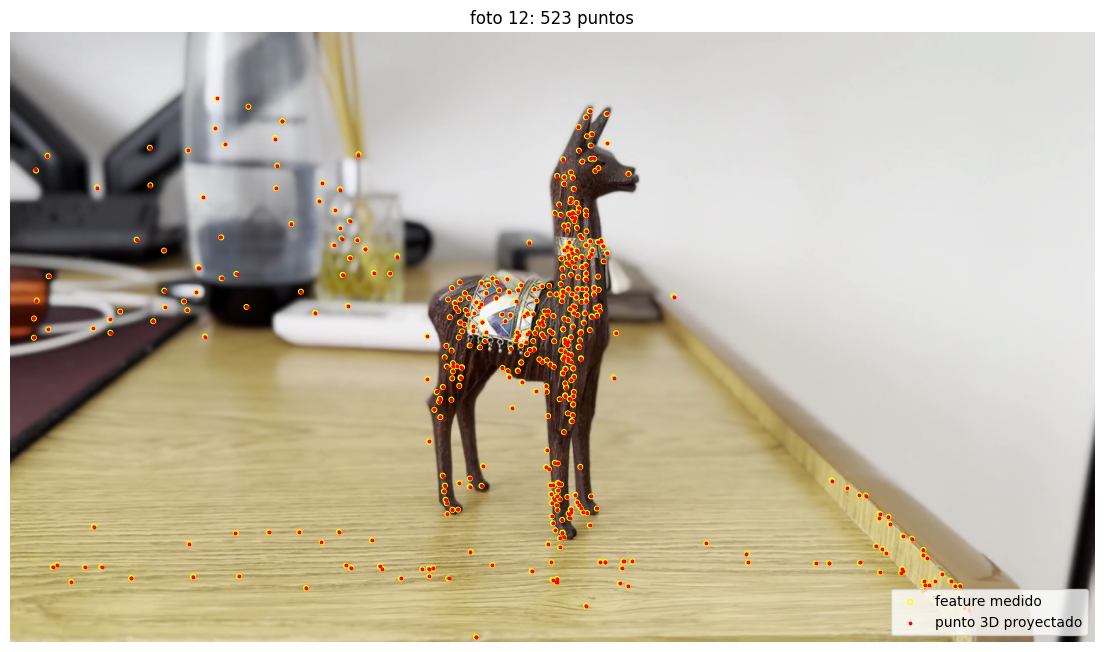

In [23]:
fr = sorted(camaras)[len(camaras) // 2] # Elegimos una foto del medio del recorrido
ts = [t for t in puntos if fr in {g for g, _ in tracks[t]}] # Buscamos los puntos 3D que se ven en esa foto
# Proyectamos los puntos 3D sobre la foto
uv_proy, _ = proyectar_P(P_de(camaras[fr], f), np.array([puntos[t] for t in ts]))
# Tomamos dónde se midió cada feature originalmente
uv_med = np.array([xy[fr][dict(tracks[t])[fr]] for t in ts])
plt.figure(figsize=(14, 8)); plt.imshow(fotos[fr])
# Comparamos: si la reconstrucción es buena, los puntos rojos caen dentro de los círculos amarillos
plt.scatter(*uv_med.T, s=12, facecolors="none", edgecolors="yellow", lw=0.8, label="feature medido")
plt.scatter(*uv_proy.T, s=3, c="red", label="punto 3D proyectado")
plt.legend(loc="lower right"); plt.axis("off"); plt.title(f"foto {fr}: {len(ts)} puntos"); plt.show()

### **Respuestas**

Para responder cada punto armé una función que vuelve a correr todo el flujo de arriba cambiando solo lo que pide el enunciado, y devuelve una fila con las cantidades de cada etapa. Así cada experimento arranca del original y no hace falta restablecer nada a mano. Primero corro la línea de base sin cambios.

In [24]:
import json, io, contextlib

# Para cada experimento vuelvo a correr todo el flujo de arriba con un cambio puntual en el código.
# Leo las celdas de código del propio notebook, reemplazo el texto indicado y las ejecuto en un
# namespace aparte, así no piso las variables de la reconstrucción principal.
# Salteo las celdas que solo dibujan con plotly (la animación y las vistas 3D) porque no cambian nada del modelo.
NOTEBOOK = "Tarea 2 - Structure from Motion.ipynb"

def correr_sfm(cambios={}):
    celdas = json.load(open(NOTEBOOK))["cells"]
    fin = next(k for k, c in enumerate(celdas) if "### **Respuestas**" in "".join(c["source"]))
    fuentes = ["".join(c["source"]) for c in celdas[:fin] if c["cell_type"] == "code"]
    fuentes = [s for s in fuentes if "go.Figure" not in s and "uv_proy" not in s]
    for viejo, nuevo in cambios.items():
        assert any(viejo in s for s in fuentes), viejo
        fuentes = [s.replace(viejo, nuevo) for s in fuentes]

    cv2.setRNGSeed(0)  # RANSAC de OpenCV usa números al azar, fijo la semilla para comparar corridas
    ns, tiempos = {}, {"sift": 0, "matching": 0, "sfm": 0}
    show = plt.show; plt.show = lambda *a, **k: plt.close("all")
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            for s in fuentes:
                t0 = time.time()
                exec(s, ns)
                etapa = "sift" if "SIFT_create" in s else "matching" if "knnMatch" in s else "sfm" if "registrar_siguiente" in s or "max_iter=150" in s else None
                if etapa: tiempos[etapa] += time.time() - t0
    finally:
        plt.show = show
    pares = ns["pares"]
    return dict(ns=ns, N=ns["N"], features=sum(map(len, ns["kps"])),
                lowe=sum(len(r["a"]) for r in pares.values()), verif=sum(int(r["ok"].sum()) for r in pares.values()),
                pares=len(pares), tracks=len(ns["tracks"]), camaras=len(ns["camaras"]), puntos=len(ns["puntos"]),
                error=ns["error_reproyeccion"]().mean(), f=ns["f"], **tiempos)

def tabla(filas):
    print(f"{'corrida':14s} {'features':>8s} {'pares':>6s} {'p. Lowe':>8s} {'p. verif':>8s} {'%RANSAC':>8s} {'tracks':>7s} {'cámaras':>8s} {'puntos':>7s} {'error px':>8s} {'t SIFT':>7s} {'t match':>8s} {'t SfM':>7s}")
    for nombre, r in filas:
        print(f"{nombre:14s} {r['features']:8d} {r['pares']:6d} {r['lowe']:8d} {r['verif']:8d} {r['verif'] / r['lowe']:8.0%} {r['tracks']:7d} "
              f"{r['camaras']:4d}/{r['N']:<3d} {r['puntos']:7d} {r['error']:8.2f} {r['sift']:6.1f}s {r['matching']:7.1f}s {r['sfm']:6.1f}s")

base = correr_sfm()
tabla([("base", base)])

corrida        features  pares  p. Lowe p. verif  %RANSAC  tracks  cámaras  puntos error px  t SIFT  t match   t SfM
base              21721    185    33278    21379      64%    3764   24/24     2699     0.29    1.5s     1.2s   33.0s


**1.- Otro video (punto adicional con video propio) Reconstruya otra escena con un video del repositorio de VGGT o con un video propio. ¿Qué zonas de la escena tienen menos puntos y por qué?**

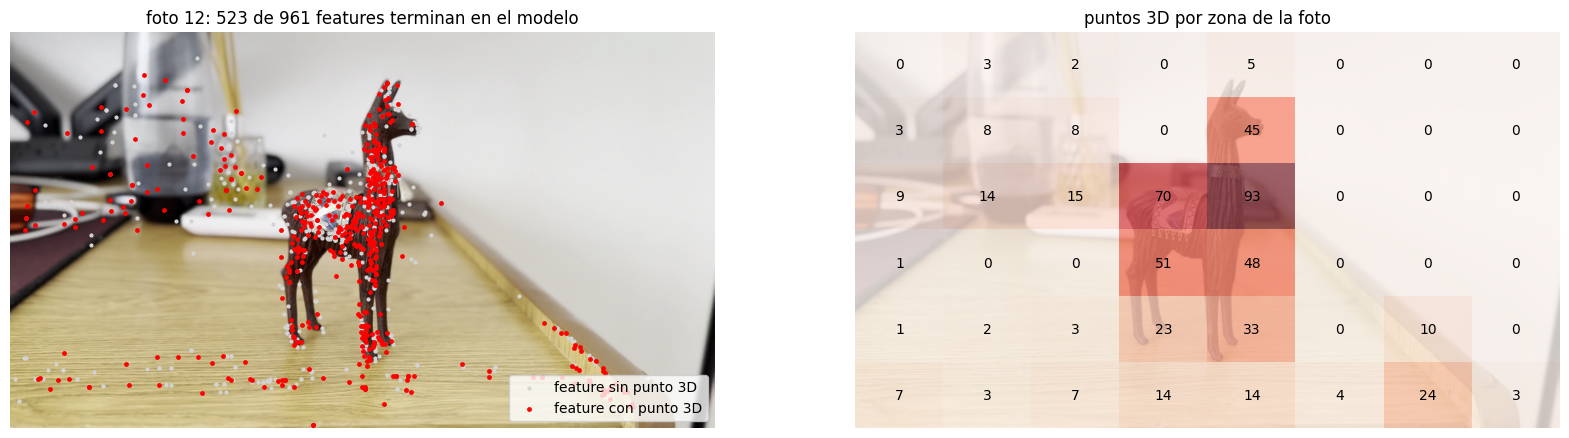

fracción de features que terminan en un punto 3D por foto: media 44%, min 25%, max 54%


In [ ]:
# Uso la reconstrucción principal.
# En una foto del medio del video marco todos los features SIFT, distinguiendo en color los que
# terminaron siendo un punto 3D del modelo final, así se ve qué zonas aportan puntos y cuáles no.
fr = sorted(camaras)[len(camaras) // 2]
en_modelo = np.array([track_de[fr].get(k) in puntos for k in range(len(xy[fr]))])
fig, ax = plt.subplots(1, 2, figsize=(20, 6))
ax[0].imshow(fotos[fr])
ax[0].scatter(*xy[fr][~en_modelo].T, s=4, c="lightgray", label="feature sin punto 3D")
ax[0].scatter(*xy[fr][en_modelo].T, s=6, c="red", label="feature con punto 3D")
ax[0].legend(loc="lower right"); ax[0].axis("off")
ax[0].set_title(f"foto {fr}: {en_modelo.sum()} de {len(en_modelo)} features terminan en el modelo")

# Cuento cuántos puntos 3D caen en cada celda de una grilla de 8 × 6 sobre la foto
cuenta, _, _ = np.histogram2d(xy[fr][en_modelo][:, 1], xy[fr][en_modelo][:, 0], bins=[6, 8], range=[[0, H], [0, W]])
ax[1].imshow(fotos[fr], alpha=0.5)
ax[1].imshow(cuenta, cmap="Reds", alpha=0.6, extent=[0, W, H, 0])
for (i, j), c in np.ndenumerate(cuenta):
    ax[1].text((j + 0.5) * W / 8, (i + 0.5) * H / 6, int(c), ha="center", va="center", fontsize=10)
ax[1].axis("off"); ax[1].set_title("puntos 3D por zona de la foto")
plt.show()

# Mismo análisis para todas las fotos registradas: qué fracción de los features termina en el modelo
frac = [np.mean([track_de[g].get(k) in puntos for k in range(len(xy[g]))]) for g in sorted(camaras)]
print(f"fracción de features que terminan en un punto 3D por foto: media {np.mean(frac):.0%}, min {np.min(frac):.0%}, max {np.max(frac):.0%}")

**Resultado**

Con un video personal de una llama de madera arriba de mi escritorio grabado en modo cine, la reconstrucción registra las 24 cámaras y deja 2699 puntos con un error medio de 0,29 px. En la foto 12, 523 de los 961 features terminan en un punto 3D, y en promedio en todas las fotos registradas llega al modelo el 44% de los features.

La mayoría de los puntos se concentran sobre la llama, sobre todo en la mantita del lomo y el collar que tienen dibujos con mucho contraste. Las zonas con menos puntos son la pared blanca, que queda en cero en casi toda la mitad derecha de la grilla, y la madera de la mesa. La pared es lisa y sin textura, así que SIFT no puede detectar nada. La mesa sí tiene vetas, pero son repetitivas y se ven muy de costado, entonces el descriptor de un punto se parece al de muchos otros y el test de Lowe lo descarta por ambiguo. Los objetos del fondo (botella, aromatizador, soporte, lentes, control, etc.) aportan pocos puntos porque están fuera de foco por el modo cine.

En resumen SfM reconstruye bien donde hay textura que se repite poco y se ve desde varias fotos, y deja huecos en superficies lisas, repetitivas o desenfocadas.

**2.- Cinco vecinos En bf.knnMatch, reemplace k=2 por k=5. ¿Cambian los resultados? Explique por qué.**

In [26]:
# Con k=5 knnMatch devuelve 5 vecinos por descriptor, así que el "for m, n in" original rompe al desempaquetar.
# Me quedo con los dos primeros y descarto el resto con *_ para que el test de Lowe sea el mismo.
k5 = correr_sfm({"k=2) if": "k=5) if", "for m, n in bf": "for m, n, *_ in bf"})
tabla([("base (k=2)", base), ("k=5", k5)])
# Verifico que las parejas sean exactamente las mismas en todos los pares
iguales = all(np.array_equal(base["ns"]["pares"][p]["a"], k5["ns"]["pares"][p]["a"]) and np.array_equal(base["ns"]["pares"][p]["b"], k5["ns"]["pares"][p]["b"])
              for p in base["ns"]["pares"]) and base["ns"]["pares"].keys() == k5["ns"]["pares"].keys()
print("mismas parejas en todos los pares:", iguales)

corrida        features  pares  p. Lowe p. verif  %RANSAC  tracks  cámaras  puntos error px  t SIFT  t match   t SfM
base (k=2)        21721    185    33278    21379      64%    3764   24/24     2699     0.29    1.5s     1.2s   33.0s
k=5               21721    185    33278    21379      64%    3764   24/24     2699     0.29    1.5s     1.2s   33.0s
mismas parejas en todos los pares: True


**Resultado**

Con k=5 los resultados son exactamente iguales a la línea de base, las mismas 33278 parejas que pasan Lowe, las mismas 21379 verificadas, 3764 tracks, 24 cámaras y 2699 puntos. Comparando par por par, las parejas son idénticas en todos los pares. Para que corra tuve que cambiar también el for m, n por for m, n, *_ porque con k=5 cada elemento trae cinco vecinos y el desempaquetado original no funciona.

No cambia nada porque el test de Lowe solo mira el mejor vecino y el segundo. BFMatcher devuelve los vecinos ordenados por distancia, así que con k=5 los dos primeros son los mismos que con k=2 y los otros tres se descartan sin usarse. El tiempo tampoco cambia, porque el algoritmo de fuerza bruta igual calcula la distancia contra todos los descriptores de la otra foto y quedarse con 5 en vez de 2 es despreciable en tiempo. Pedir más vecinos tendría sentido si el criterio usara más información, por ejemplo comparar contra el tercero o aceptar varias parejas por punto, pero con este test no aporta valor.

**3.- Test de Lowe: Reemplace 0.8 por 0.6 y luego por 0.95. ¿Cómo varían las parejas y los puntos 3D? ¿Por qué aceptar más parejas no produce más puntos?**

In [27]:
lowe06 = correr_sfm({"0.8 * n.distance": "0.6 * n.distance"})
lowe095 = correr_sfm({"0.8 * n.distance": "0.95 * n.distance"})
tabla([("Lowe 0.6", lowe06), ("base (0.8)", base), ("Lowe 0.95", lowe095)])

corrida        features  pares  p. Lowe p. verif  %RANSAC  tracks  cámaras  puntos error px  t SIFT  t match   t SfM
Lowe 0.6          21721    104    16018    13062      82%    4100   24/24     2944     0.25    1.5s     0.4s   27.3s
base (0.8)        21721    185    33278    21379      64%    3764   24/24     2699     0.29    1.5s     1.2s   33.0s
Lowe 0.95         21721    185    96353    23187      24%    2986    9/24      558     0.27    1.5s     2.0s    3.2s


**Resultado**

Con 0.6 pasan Lowe 16018 parejas (contra 33278 de la base), quedan 104 pares de fotos en lugar de 185 y el 82% de las parejas pasa RANSAC. Se registran las 24 cámaras y salen 2944 puntos, más que la base. Con 0.95 las parejas que pasan Lowe se triplican a 96353, pero solo el 24% sobrevive a RANSAC (23187, apenas más que la base), los tracks bajan a 2986, se registran nada más que 9 de las 24 cámaras y el modelo queda en 558 puntos.

Me llama la atención que el umbral más exigente dé más puntos que el original. El test de Lowe filtra por ambigüedad, si el segundo vecino está casi tan cerca como el primero no hay forma de saber cuál es el correcto. Al subir a 0.95 entran justamente esas parejas dudosas, que en este video seguramente salen de la madera de la mesa y de los dibujos repetidos de la llama, y casi todas son incorrectas. RANSAC se queda con el 24%, pero con umbral de 1 px una pareja mala que cae cerca de la recta epipolar igual pasa. El daño grande aparece en los tracks, porque una sola pareja mala en el union-find junta dos grupos distintos, el grupo suele terminar con dos features de la misma foto y se descarta entero, por eso con más parejas hay menos tracks. Con menos tracks, PnP deja de encontrar suficientes correspondencias 2D-3D y solo se registran 9 cámaras. Con 0.6 pasa lo contrario, se pierden parejas buenas y pares de fotos lejanas, pero las que quedan son limpias y se descartan menos tracks. O sea que para los puntos 3D importa más la calidad de las parejas que la cantidad.

**4.- Menos features: reemplace cv2.SIFT_create(3000) por cv2.SIFT_create(1000). ¿Qué ocurre con los puntos 3D y el tiempo?**

In [28]:
sift1000 = correr_sfm({"cv2.SIFT_create(3000)": "cv2.SIFT_create(1000)"})
# En este video SIFT encuentra entre 687 y 1132 features por foto, así que el tope de 1000 casi no corta nada.
# Agrego una corrida con 500 para ver qué pasa cuando el tope sí se nota.
sift500 = correr_sfm({"cv2.SIFT_create(3000)": "cv2.SIFT_create(500)"})
tabla([("base (3000)", base), ("SIFT 1000", sift1000), ("SIFT 500", sift500)])
for nombre, tope, r in [("base (3000)", 3000, base), ("SIFT 1000", 1000, sift1000), ("SIFT 500", 500, sift500)]:
    print(f"{nombre:12s} fotos que llegan al tope: {sum(len(k) >= tope for k in r['ns']['kps']):2d}/24 | tiempo total {r['sift'] + r['matching'] + r['sfm']:.1f} s")

corrida        features  pares  p. Lowe p. verif  %RANSAC  tracks  cámaras  puntos error px  t SIFT  t match   t SfM
base (3000)       21721    185    33278    21379      64%    3764   24/24     2699     0.29    1.5s     1.2s   33.0s
SIFT 1000         21539    185    33033    21142      64%    3739   24/24     2848     0.28    1.5s     1.2s   31.9s
SIFT 500          12001    184    21477    12774      59%    1917   24/24     1284     0.28    1.4s     1.1s   18.8s
base (3000)  fotos que llegan al tope:  0/24 | tiempo total 35.6 s
SIFT 1000    fotos que llegan al tope:  5/24 | tiempo total 34.6 s
SIFT 500     fotos que llegan al tope: 24/24 | tiempo total 21.3 s


**Resultado**

Con SIFT_create(1000) el modelo queda prácticamente igual, 2848 puntos contra 2699 y 24 cámaras, y el tiempo total pasa de 35,6 s a 34,6 s. Como en este video SIFT encuentra entre 687 y 1132 features por foto, el tope de 1000 solo corta en 5 de las 24 fotos y el total de features baja apenas de 21721 a 21539. Para ver el efecto cuando el tope sí corta probé también con 500, ahí todas las fotos llegan al tope, los features caen a la mitad (12001), los puntos 3D bajan a 1284 y el tiempo total a 21,3 s.

La diferencia de puntos con 1000 es chica y se explica porque cambiar unos pocos features mueve un poco el orden de las fotos, el bundle adjustment y la limpieza, y eso termina cambiando un poco la cantidad de puntos. Con 500 la caída se nota, vemos que menos features dan menos parejas, menos tracks y menos puntos. Igual se siguen registrando todas las cámaras, porque SIFT se queda con los features de mayor respuesta, que son los más estables y los que más se repiten entre fotos. Del tiempo, lo que más baja es el SfM incremental (de 33 s a 19 s), porque el bundle adjustment escala con la cantidad de puntos y observaciones. La detección de SIFT casi no cambia porque igual recorre la pirámide de escalas entera y recién al final se queda con los mejores, y el matching ya era rápido.

En resumen menos features hacen que el procesamiento sea más rápido a costa de menos puntos 3D.

**5.- Menos fotografías: Reemplace N = 24 por N = 12. ¿Se registran todas las cámaras?**

In [29]:
n12 = correr_sfm({"N = 24 ": "N = 12 "})
tabla([("base (N=24)", base), ("N=12", n12)])
print("fotos registradas con N=12:", sorted(n12["ns"]["camaras"]))
print("fotos sin registrar:", sorted(set(range(n12["N"])) - set(n12["ns"]["camaras"])))

corrida        features  pares  p. Lowe p. verif  %RANSAC  tracks  cámaras  puntos error px  t SIFT  t match   t SfM
base (N=24)       21721    185    33278    21379      64%    3764   24/24     2699     0.29    1.5s     1.2s   33.0s
N=12              11102     65     8094     4693      58%    1925   12/12     1639     0.20    0.8s     0.5s   13.8s
fotos registradas con N=12: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
fotos sin registrar: []


**Resultado**

Sí, con N=12 se registran las 12 cámaras, ninguna queda afuera. El modelo tiene 1639 puntos (61% de la base), 1925 tracks y un error medio de 0,20 px, y el SfM tarda 13,8 s contra 33 s.

Como en el video el movimiento es lento alrededor de la llama, aun si tomamos la mitad de fotos, que implica el doble de separación entre ellas, vemos que fotos consecutivas siguen compartiendo bastante y PnP encuentra suficientes correspondencias para ubicar las cámaras. Lo que se pierde es densidad, porque cada zona se ve en menos fotos, hay menos tracks con dos o más observaciones y por lo tanto menos puntos para triangular.

**6.- Ángulo de triangulación: En triangular_nuevos, reemplace > 1.5 por > 3. ¿Cuántos puntos se pierden? ¿Por qué un ángulo pequeño da una profundidad poco confiable?**

corrida        features  pares  p. Lowe p. verif  %RANSAC  tracks  cámaras  puntos error px  t SIFT  t match   t SfM
base (1.5°)       21721    185    33278    21379      64%    3764   24/24     2699     0.29    1.5s     1.2s   33.0s
ángulo 3°         21721    185    33278    21379      64%    3764   24/24     2473     0.29    1.5s     1.2s   28.0s
puntos perdidos: 226 (8% del modelo base)
en el modelo base 21% de los puntos tienen ángulo máximo menor a 3° (mediana 6.5°)


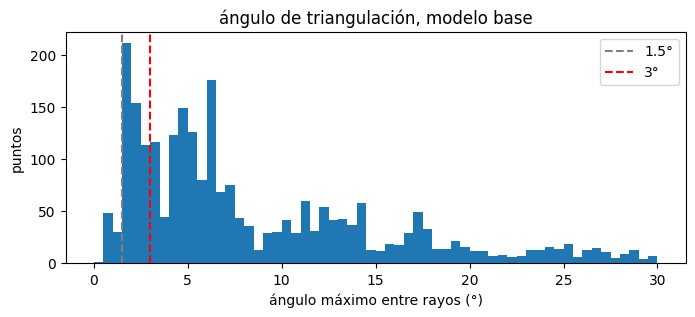

In [30]:
ang3 = correr_sfm({")) > 1.5:": ")) > 3:"})
tabla([("base (1.5°)", base), ("ángulo 3°", ang3)])
print(f"puntos perdidos: {base['puntos'] - ang3['puntos']} ({1 - ang3['puntos'] / base['puntos']:.0%} del modelo base)")

# Para entender qué puntos se van, calculo el ángulo máximo entre rayos de cada punto del modelo base
ns = base["ns"]
def angulo_max(t):
    rayos = [(ns["puntos"][t] - ns["centro"](ns["camaras"][fr])) for fr, _ in ns["tracks"][t] if fr in ns["camaras"]]
    rayos = [r / np.linalg.norm(r) for r in rayos]
    return np.degrees(np.arccos(np.clip(min(a @ b for a in rayos for b in rayos), -1, 1)))
angs = np.array([angulo_max(t) for t in ns["puntos"]])
print(f"en el modelo base {np.mean(angs < 3):.0%} de los puntos tienen ángulo máximo menor a 3° (mediana {np.median(angs):.1f}°)")
plt.figure(figsize=(8, 3)); plt.hist(angs, bins=60, range=(0, 30))
plt.axvline(1.5, color="gray", ls="--", label="1.5°"); plt.axvline(3, color="red", ls="--", label="3°")
plt.xlabel("ángulo máximo entre rayos (°)"); plt.ylabel("puntos"); plt.legend(); plt.title("ángulo de triangulación, modelo base"); plt.show()

**Resultado**

Con el umbral en 3° el modelo queda con 2473 puntos en lugar de 2699, se pierden 226 puntos, un 8% del modelo base. Las cámaras siguen siendo 24 y el error medio no cambia (0,29 px).

En el histograma del modelo base el 21% de los puntos tiene un ángulo máximo menor a 3°, pero se pierde mucho menos que eso. Pasa porque la función triangular_nuevos se vuelve a llamar cada vez que entra una cámara, así que un track rechazado por ángulo chico con las dos primeras fotos se puede triangular más adelante cuando lo ve una cámara más alejada. Los que se pierden del todo son los que solo se ven desde posiciones muy cercanas entre sí.

Con un ángulo chico los dos rayos que se cruzan para armar el punto 3D son casi paralelos. Entonces un error chico en un feature, de un píxel por ejemplo, mueve mucho el cruce en profundidad. El filtro de 4 px no lo detecta, porque el punto se corre casi sobre los mismos rayos y sigue reproyectando bien en las dos fotos, por eso hace falta el filtro de ángulo. Con un umbral de ángulo más alto el modelo queda con menos puntos, pero mejor ubicados y más confiables.